# Limpieza y visualización de datos de emisiones de CO₂ per cápita en Colombia

**Proyecto:** Análisis de las emisiones de CO₂ mediante regresión lineal.


## Objetivo

Realizar la limpieza y exploración de los datos de emisiones de CO₂ per cápita de Colombia, mediante el uso de Python, para identificar su comportamiento a través de los años y representar la información mediante gráficos estadísticos.

Librerías cargadas correctamente
Columnas disponibles:
['Entity', 'Code', 'Year', 'CO₂ emissions per capita']

Tamaño de los datos:
(27238, 4)

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27238 entries, 0 to 27237
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Entity                    27238 non-null  object 
 1   Code                      26087 non-null  object 
 2   Year                      27238 non-null  int64  
 3   CO₂ emissions per capita  27238 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 851.3+ KB

Valores faltantes:
Entity                         0
Code                        1151
Year                           0
CO₂ emissions per capita       0
dtype: int64
Columna de emisiones: CO₂ emissions per capita
Valores faltantes antes de limpiar:
Year              0
co2_per_capita    0
dtype: int64

Datos después de la limpieza:
 

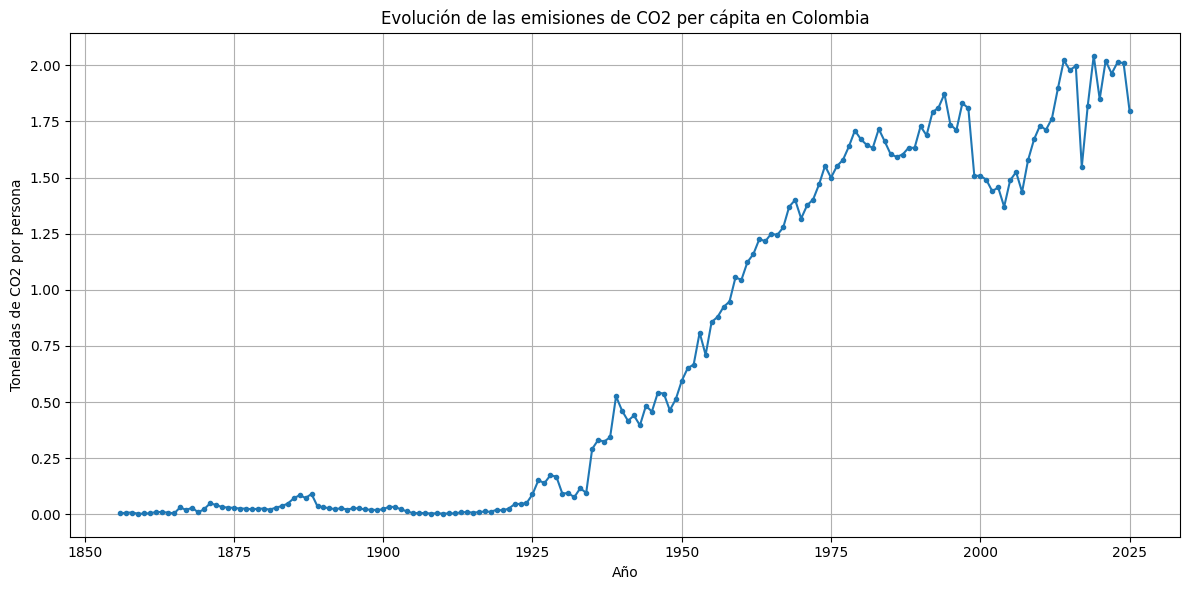

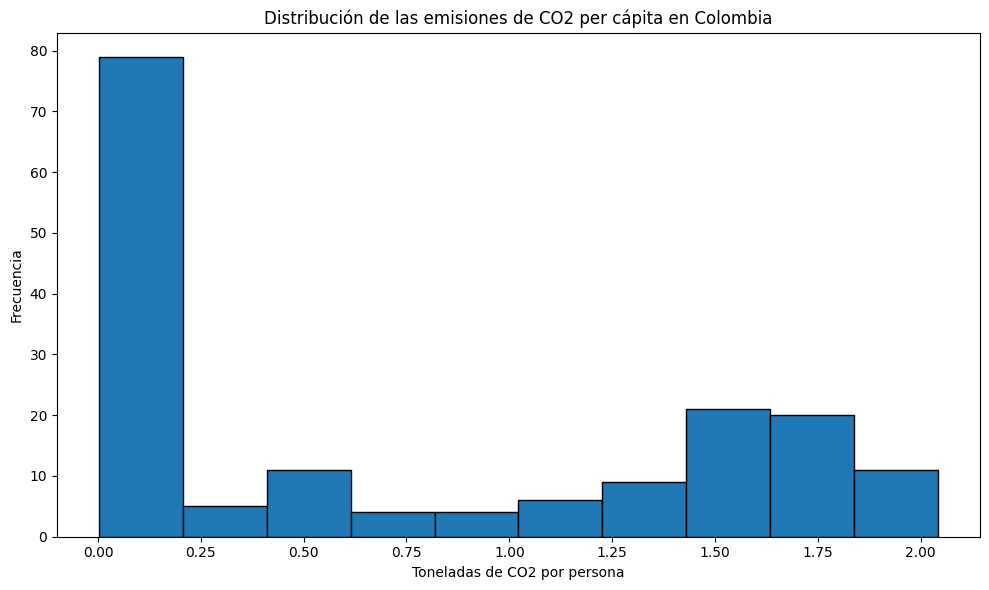

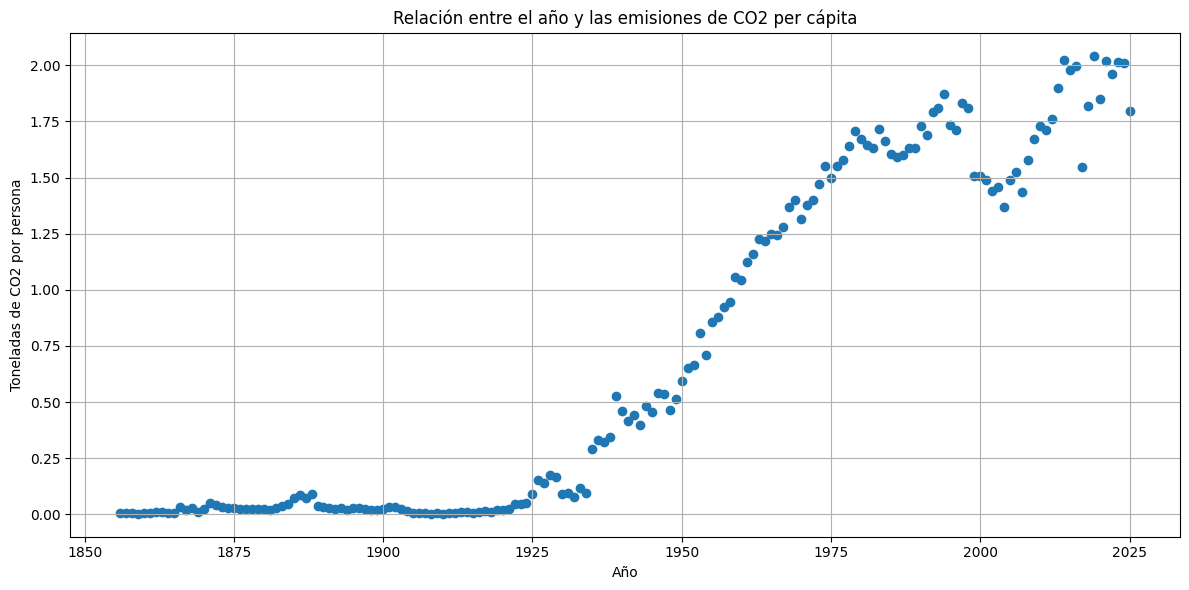

Archivo limpio creado correctamente


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# Importar las librerías necesarias

import pandas as pd
import matplotlib.pyplot as plt

print("Librerías cargadas correctamente")

# Enlace de Our World in Data

url = "https://ourworldindata.org/grapher/co-emissions-per-capita.csv?v=1&csvType=full&useColumnShortNames=false"

# Leer el archivo CSV

df = pd.read_csv(
    url,
    storage_options={
        "User-Agent": "Our World In Data data fetch/1.0"
    }
)

# Mostrar los primeros registros

df.head()


# Revisar  columnas

print("Columnas disponibles:")
print(df.columns.tolist())

# Revisar el tamaño del conjunto de datos

print("\nTamaño de los datos:")
print(df.shape)

print("\nInformación general:")
df.info()

print("\nValores faltantes:")
print(df.isnull().sum())


# Identificar las columnas del archivo

columna_pais = "Entity"
columna_anio = "Year"

# Identificar la columna de emisiones per cápita
columna_emisiones = next(
    (col for col in df.columns
     if "per capita" in col.lower()
     or "per_capita" in col.lower()),
    None
)

print("Columna de emisiones:", columna_emisiones)

# Verificar que se encontró la variable
if columna_emisiones is None:
    raise ValueError("No se encontró la columna de emisiones per cápita")

# Seleccionar los registros de Colombia
colombia = df[df[columna_pais] == "Colombia"].copy()

# Conservar solamente las variables necesarias
colombia = colombia[
    [columna_anio, columna_emisiones]
].copy()

# Cambiar los nombres para facilitar el trabajo
colombia.columns = ["Year", "co2_per_capita"]

# Mostrar los datos seleccionados
colombia.head()

# Convertir las variables a formato numérico
colombia["Year"] = pd.to_numeric(
    colombia["Year"], errors="coerce"
)

colombia["co2_per_capita"] = pd.to_numeric(
    colombia["co2_per_capita"], errors="coerce"
)

# Revisar valores faltantes antes de limpiar
print("Valores faltantes antes de limpiar:")
print(colombia.isnull().sum())

# Eliminar registros incompletos
colombia = colombia.dropna(
    subset=["Year", "co2_per_capita"]
)

# Eliminar registros duplicados
colombia = colombia.drop_duplicates()

# Ordenar cronológicamente
colombia = colombia.sort_values("Year")

# Reiniciar índices
colombia = colombia.reset_index(drop=True)

# Mostrar el resultado
print("\nDatos después de la limpieza:")
print(colombia.head())

print("\nCantidad de registros:", len(colombia))
print("Año inicial:", int(colombia["Year"].min()))
print("Año final:", int(colombia["Year"].max()))


# Gráfico 1: evolución de emisiones

colombia["co2_per_capita"].describe()


plt.figure(figsize=(12, 6))

plt.plot(
    colombia["Year"],
    colombia["co2_per_capita"],
    marker="o",
    markersize=3
)

plt.title("Evolución de las emisiones de CO2 per cápita en Colombia")
plt.xlabel("Año")
plt.ylabel("Toneladas de CO2 por persona")

plt.grid(True)
plt.tight_layout()
plt.show()

#segundo grafico

plt.figure(figsize=(10, 6))

plt.hist(
    colombia["co2_per_capita"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribución de las emisiones de CO2 per cápita en Colombia")
plt.xlabel("Toneladas de CO2 por persona")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

#tercer grafico

plt.figure(figsize=(12, 6))

plt.scatter(
    colombia["Year"],
    colombia["co2_per_capita"]
)

plt.title("Relación entre el año y las emisiones de CO2 per cápita")
plt.xlabel("Año")
plt.ylabel("Toneladas de CO2 por persona")

plt.grid(True)
plt.tight_layout()
plt.show()



# Exportar los datos limpios

colombia.to_csv(
    "emisiones_colombia_limpio.csv",
    index=False
)

print("Archivo limpio creado correctamente")


from google.colab import files

files.download("emisiones_colombia_limpio.csv")


